# Evaluación Comparativa Unificada: LMS vs. RLS y Análisis de Ventanas Ruidosas (SQI)

Este notebook integra un **control de calidad de señal (SQI)** con la evaluación estadística sobre `IEEEPPG_TEST.ts` para comparar **NLMS y VS-LMS reoptimizados con características compartidas** (según `pipeline_optimization_and_evaluation.ipynb`), **LMS** del Proyecto 1 con `SHARED_STRUCTURAL_PARAMS`, y el **RLS optimizado** del Proyecto 2.

| # | Sección | Objetivo |
|---|---|---|
| 1 | Carga de datos y configuración | Carga de `TRAIN`/`TEST` y modelos óptimos. |
| 2 | **SQI (criterio dual)** | Descartar ventanas con **Energía ACC alta Y SNR de pico baja**, con umbrales calibrados en *train* y sin usar etiquetas. |
| 3 | Evaluación global vs. filtrada | AAE, mediana, RMSE, P90 y outliers con todas las ventanas y sólo con las retenidas (detector propio y común). |
| 3b | **Control del SQI** | ¿El SQI descarta ventanas más difíciles que el azar? Sensibilidad de umbrales. |
| 4 | Intervalos de confianza | Bootstrap por sujeto de la diferencia de AAE. |
| 5 | Dispersión y rendimiento por sujeto | Marcando ventanas descartadas. |
| 6 | Régimen de movimiento | Degradación según energía del acelerómetro. |

## 1. Carga de Datos y Configuración de Modelos Óptimos

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

# --- Resolución de rutas del proyecto ---
cwd = os.path.abspath(os.getcwd())
if os.path.basename(cwd) in ("implementation", "restructured_implementation"):
    IMPL_DIR, PROJECT_ROOT = cwd, os.path.abspath(os.path.join(cwd, ".."))
elif os.path.isdir(os.path.join(cwd, "implementation")):
    IMPL_DIR, PROJECT_ROOT = os.path.join(cwd, "implementation"), cwd
else:
    IMPL_DIR, PROJECT_ROOT = cwd, cwd
for p in (IMPL_DIR, PROJECT_ROOT):
    if p not in sys.path:
        sys.path.insert(0, p)

try:
    from implementation import (
        FS, WIN, load_ts, get_participant_groups, preprocess_signal,
        snr_weighted_late_fusion, zero_padded_periodogram_bpm, estimate_cardiac_snr,
        objective_function, HeartRateEstimatorModel,
    )
    from implementation import LMS_algorithms as LMSA
except ImportError:
    from dataset_preparation import FS, WIN, load_ts, get_participant_groups
    from preprocessing import preprocess_signal
    from fusion import snr_weighted_late_fusion, estimate_cardiac_snr
    from bpm_detection import zero_padded_periodogram_bpm, objective_function
    from pipeline import HeartRateEstimatorModel
    import LMS_algorithms as LMSA

plt.rcParams.update({
    "figure.figsize": (13, 5), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

def find_dataset_file(filename):
    search_dirs = [
        os.getcwd(), PROJECT_ROOT, IMPL_DIR,
        os.path.join(PROJECT_ROOT, "Proyecto_1_submission"),
        "/content", "/content/drive/MyDrive",
    ]
    for d in search_dirs:
        cand = os.path.join(d, filename)
        if os.path.isfile(cand):
            return cand
    raise FileNotFoundError(f"No se encontró '{filename}' en {search_dirs}")

X_train, y_train = load_ts(find_dataset_file("IEEEPPG_TRAIN.ts"))
X_test, y_test = load_ts(find_dataset_file("IEEEPPG_TEST.ts"))
train_groups = get_participant_groups(X_train)
test_groups = get_participant_groups(X_test)
subjects = np.unique(test_groups)

print(f"Train: {X_train.shape} | sujetos = {len(np.unique(train_groups))}")
print(f"Test : {X_test.shape} | sujetos = {len(subjects)}")

Train: (1768, 5, 1000) | sujetos = 12
Test : (1328, 5, 1000) | sujetos = 10


In [2]:
# ----------------------------- Configuración General -----------------------------
SEED = 0
SAVE_FIGS = True
FIG_DIR = "figuras_comparacion_unificada"
LMS_REF = "nlms"
N_BOOT = 2000
OUTLIER_BPM = 10.0
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    if SAVE_FIGS:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")

# ----------------------------- RLS Optimizado (Proyecto 2) -----------------------------
RLS_M = 7
RLS_PARAMS = dict(
    delay_step=4,
    N_eff=1409.281222670354,
    delta=5.11410341560248,
    diag_load=0.14339015026730578,
    huber_c=2.5014879715311853,
    warm_start_ratio=0.0,
)
RLS_HR = dict(hr_algorithm="periodogram", hr_params=dict(nfft=8192, window_type="hann"))

# ----------------------------- NLMS reoptimizado (Proyecto 2) --------------------------
NLMS_M = 16
NLMS_PARAMS = dict(
    delay_step=2,
    mu=0.01459,
    delta=2.63535,
    huber_c=1.68220,
    warm_start_ratio=0.5,
)
NLMS_HR = dict(hr_algorithm="periodogram", hr_params=dict(nfft=8192, window_type="hamming"))

# ----------------------------- VS-LMS reoptimizado (Proyecto 2) ------------------------
VS_LMS_M = 13
VS_LMS_PARAMS = dict(
    delay_step=2,
    mu_max=0.15297,
    mu_min=0.01317,
    alpha=0.97338,
    gamma=0.00012,
    delta=0.79051,
    huber_c=1.80559,
    warm_start_ratio=0.5,
)
VS_LMS_HR = dict(hr_algorithm="periodogram", hr_params=dict(nfft=8192, window_type="hamming"))

# ----------------------------- Características estructurales compartidas (LMS estándar) --
SHARED_STRUCTURAL_PARAMS = dict(
    delay_step=RLS_PARAMS["delay_step"],
    huber_c=RLS_PARAMS["huber_c"],
    warm_start_ratio=RLS_PARAMS["warm_start_ratio"],
)

models = {
    "lms": HeartRateEstimatorModel.from_project1_optimal("lms", **SHARED_STRUCTURAL_PARAMS),
    "nlms": HeartRateEstimatorModel(
        lms_algorithm="nlms", M=NLMS_M, lms_params=dict(NLMS_PARAMS), **NLMS_HR),
    "vs_lms": HeartRateEstimatorModel(
        lms_algorithm="vs_lms", M=VS_LMS_M, lms_params=dict(VS_LMS_PARAMS), **VS_LMS_HR),
    "rls": HeartRateEstimatorModel(
        lms_algorithm="rls", M=RLS_M, lms_params=dict(RLS_PARAMS), **RLS_HR),
}

CV_AAE = {"base": 12.52, "lms": 5.18, "nlms": 3.82, "vs_lms": 4.04, "rls": 3.66}
ORDER = ["base", "lms", "nlms", "vs_lms", "rls"]
LABELS = {"base": "Sin filtro", "lms": "LMS", "nlms": "NLMS", "vs_lms": "VS-LMS", "rls": "RLS"}
COLORS = {"base": "#7f7f7f", "lms": "#9467bd", "nlms": "#1f77b4", "vs_lms": "#2ca02c", "rls": "#d62728"}

# ----------------------------- Parámetros del SQI (criterio dual) -----------------------------
# Se descarta una ventana si:  E_ACC > percentil SQI_PCT_ACC de TRAIN   Y   SNR_pico < percentil SQI_PCT_SNR de TRAIN
SQI_PCT_ACC = 75
SQI_PCT_SNR = 25
N_RANDOM_CTRL = 1000   # réplicas del control de descarte aleatorio

## 2. Control de calidad de señal (SQI)

Una ventana se **descarta** sólo si cumple las dos condiciones a la vez (AND):

1. **Energía dinámica del acelerómetro** $E_{ACC}$ alta: potencia AC media de los 3 ejes (sin gravedad DC), calculada sobre la señal cruda.
2. **SNR de pico** baja: relación en dB entre la potencia concentrada alrededor del pico dominante ($\pm 0.15$ Hz) y el resto de la banda $[0.5, 4]$ Hz, medida sobre la PPG preprocesada y fusionada por SNR (`estimate_cardiac_snr` de `fusion.py`). Es baja cuando el espectro no tiene un componente periódico claro.

**Qué cambió respecto de la versión anterior y por qué**
- La SNR anterior comparaba la banda $[0.65, 3.5]$ Hz contra el resto sobre la PPG cruda, con un umbral fijo de $-6$ dB. Casi ninguna ventana tenía una SNR tan baja (en tu corrida: 0 ventanas a $-6$ dB y 2–6 entre $-3$ y $-1$ dB), así que el AND **nunca se activaba** y el filtrado no filtraba nada. Además esa métrica mide energía en banda, no concentración cardíaca: el movimiento también cae en esa banda.
- Ahora **ambos umbrales son percentiles de *train***, de modo que el criterio siempre tiene una tasa de descarte razonable y no depende de la escala de una métrica que no conocíamos.

**Reglas para que el SQI sea una comparación válida y no un sesgo**
- No usa etiquetas (`y`): sólo mira la entrada.
- No depende del algoritmo: **la misma máscara se aplica a LMS, NLMS, VS-LMS y RLS**.
- Los umbrales se calibran en *train* y se aplican a *test*.
- Siempre se reporta la **cobertura** (qué fracción de ventanas se conserva): filtrar mejora el AAE por construcción, así que la cifra sola no alcanza.
- En la sección 3b se verifica que el SQI descarte ventanas más difíciles que un descarte al azar de la misma cantidad.

In [3]:
def calcular_metricas_sqi(X, fs=FS):
    # Métricas por ventana, sin etiquetas y sin depender del filtro adaptativo.
    #   e_acc   : potencia AC media del acelerómetro (3 ejes), señal cruda.
    #   snr_db  : SNR de pico (dB) de la PPG preprocesada y fusionada por SNR.
    #   corr_ppg: correlación PPG1-PPG2 (indicador auxiliar, no entra en el criterio).
    X = np.asarray(X, dtype=float)
    N = len(X)

    acc_ac = X[:, 2:5, :] - np.mean(X[:, 2:5, :], axis=-1, keepdims=True)
    e_acc = np.mean(np.sum(acc_ac ** 2, axis=1), axis=-1)

    p1, p2, _ = preprocess_signal(X, fs=fs)      # ojo: fs va por nombre (el 2º argumento posicional es `lo`)
    snr_db = np.empty(N)
    corr_ppg = np.empty(N)
    for i in range(N):
        d = snr_weighted_late_fusion(p1[i], p2[i], fs=fs)
        snr_db[i] = 10.0 * np.log10(estimate_cardiac_snr(d, fs=fs) + 1e-12)
        corr_ppg[i] = np.corrcoef(p1[i], p2[i])[0, 1] if np.all(np.isfinite(d)) else np.nan
    return {"e_acc": e_acc, "snr_db": snr_db, "corr_ppg": corr_ppg}


def calibrar_umbrales_sqi(met_train, pct_acc=SQI_PCT_ACC, pct_snr=SQI_PCT_SNR):
    # Umbrales = percentiles de TRAIN (sin etiquetas, sin mirar test).
    return {
        "pct_acc": pct_acc, "pct_snr": pct_snr,
        "umbral_acc": float(np.nanpercentile(met_train["e_acc"], pct_acc)),
        "umbral_snr_db": float(np.nanpercentile(met_train["snr_db"], pct_snr)),
    }


def evaluar_criterio_dual_sqi(met, umbrales):
    # Descarta si (E_ACC alta AND SNR de pico baja). Ventanas no finitas también se descartan.
    cond_acc_alta = met["e_acc"] > umbrales["umbral_acc"]
    cond_snr_baja = met["snr_db"] < umbrales["umbral_snr_db"]
    no_finito = ~np.isfinite(met["e_acc"]) | ~np.isfinite(met["snr_db"])
    mask_irrecuperable = (cond_acc_alta & cond_snr_baja) | no_finito
    mask_valida = ~mask_irrecuperable
    total = len(mask_valida)
    return {
        "total": total,
        "solo_acc_alta": int(np.sum(cond_acc_alta & ~cond_snr_baja)),
        "solo_snr_baja": int(np.sum(~cond_acc_alta & cond_snr_baja)),
        "ambos_descartadas": int(np.sum(mask_irrecuperable)),
        "retenidas": int(np.sum(mask_valida)),
        "umbral_acc": umbrales["umbral_acc"],
        "umbral_snr_db": umbrales["umbral_snr_db"],
        "e_acc": met["e_acc"], "snr_db": met["snr_db"], "corr_ppg": met["corr_ppg"],
        "cond_acc_alta": cond_acc_alta, "cond_snr_baja": cond_snr_baja,
        "mask_irrecuperable": mask_irrecuperable, "mask_valida": mask_valida,
    }


# Las métricas se calculan UNA vez (train y test); los umbrales se pueden variar sin recalcular.
met_train = calcular_metricas_sqi(X_train)
met_test = calcular_metricas_sqi(X_test)
umbrales_sqi = calibrar_umbrales_sqi(met_train)
diag_sqi = evaluar_criterio_dual_sqi(met_test, umbrales_sqi)

pcts = [5, 25, 50, 75, 95]
print("Distribución de la SNR de pico (dB) -> percentiles", pcts)
print("  Train:", np.round(np.nanpercentile(met_train["snr_db"], pcts), 2))
print("  Test :", np.round(np.nanpercentile(met_test["snr_db"], pcts), 2))
print()
print("=== DIAGNÓSTICO DE CALIDAD DE VENTANAS EN TEST (CRITERIO DUAL AND) ===")
print(f"Total de ventanas en Test         : {diag_sqi['total']}")
print(f"Umbral Energía ACC (P{SQI_PCT_ACC} Train)    : {diag_sqi['umbral_acc']:.4f}")
print(f"Umbral SNR de pico (P{SQI_PCT_SNR} Train)    : {diag_sqi['umbral_snr_db']:.2f} dB")
print(f"Solo Energía ACC alta (retenidas) : {diag_sqi['solo_acc_alta']}")
print(f"Solo SNR de pico baja (retenidas) : {diag_sqi['solo_snr_baja']}")
print(f"AMBOS criterios (descartadas)     : {diag_sqi['ambos_descartadas']} ({100*diag_sqi['ambos_descartadas']/diag_sqi['total']:.1f}%)")
print(f"Ventanas válidas retenidas        : {diag_sqi['retenidas']} ({100*diag_sqi['retenidas']/diag_sqi['total']:.1f}%)")

Distribución de la SNR de pico (dB) -> percentiles [5, 25, 50, 75, 95]
  Train: [-2.54  0.39  3.1   6.1  10.19]
  Test : [-5.1  -2.96 -1.05  0.86  4.19]

=== DIAGNÓSTICO DE CALIDAD DE VENTANAS EN TEST (CRITERIO DUAL AND) ===
Total de ventanas en Test         : 1328
Umbral Energía ACC (P75 Train)    : 2.0057
Umbral SNR de pico (P25 Train)    : 0.39 dB
Solo Energía ACC alta (retenidas) : 129
Solo SNR de pico baja (retenidas) : 691
AMBOS criterios (descartadas)     : 250 (18.8%)
Ventanas válidas retenidas        : 1078 (81.2%)


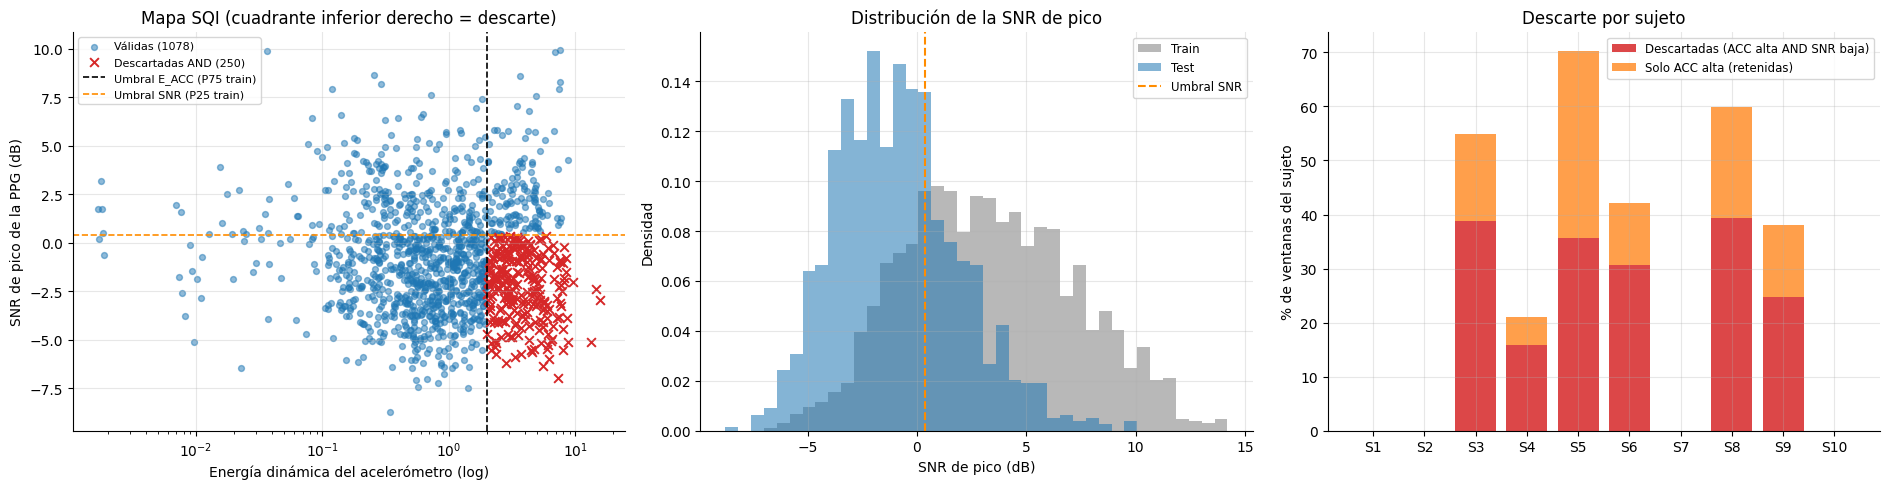


Sensibilidad del criterio dual a los percentiles (sólo conteos):


,Percentil ACC (Train),Percentil SNR (Train),Umbral ACC,Umbral SNR (dB),Descartadas (n),Descartadas (%),Retenidas (n)
0,P65,P15,1.772,-0.83,225,16.94,1103
1,P65,P25,1.772,0.39,292,21.99,1036
2,P65,P35,1.772,1.43,338,25.45,990
3,P75,P15,2.006,-0.83,190,14.31,1138
4,P75,P25,2.006,0.39,250,18.83,1078
5,P75,P35,2.006,1.43,294,22.14,1034
6,P85,P15,2.198,-0.83,167,12.58,1161
7,P85,P25,2.198,0.39,225,16.94,1103
8,P85,P35,2.198,1.43,266,20.03,1062


In [4]:
# --- Espacio SQI, distribución de la SNR y descarte por sujeto ---
m_val = diag_sqi["mask_valida"]
m_irr = diag_sqi["mask_irrecuperable"]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.0))

ax = axes[0]
ex = np.maximum(diag_sqi["e_acc"], 1e-6)
ax.scatter(ex[m_val], diag_sqi["snr_db"][m_val], c="#1f77b4", alpha=0.5, s=18, label=f"Válidas ({m_val.sum()})")
ax.scatter(ex[m_irr], diag_sqi["snr_db"][m_irr], c="#d62728", marker="x", s=40, linewidths=1.4,
           label=f"Descartadas AND ({m_irr.sum()})")
ax.axvline(diag_sqi["umbral_acc"], color="black", ls="--", lw=1.2, label=f"Umbral E_ACC (P{SQI_PCT_ACC} train)")
ax.axhline(diag_sqi["umbral_snr_db"], color="darkorange", ls="--", lw=1.2, label=f"Umbral SNR (P{SQI_PCT_SNR} train)")
ax.set_xscale("log")
ax.set_xlabel("Energía dinámica del acelerómetro (log)")
ax.set_ylabel("SNR de pico de la PPG (dB)")
ax.set_title("Mapa SQI (cuadrante inferior derecho = descarte)")
ax.legend(loc="best", fontsize=8)

ax = axes[1]
bins = np.linspace(np.nanmin([met_train["snr_db"].min(), met_test["snr_db"].min()]),
                   np.nanmax([met_train["snr_db"].max(), met_test["snr_db"].max()]), 40)
ax.hist(met_train["snr_db"], bins=bins, alpha=0.55, density=True, color="#7f7f7f", label="Train")
ax.hist(met_test["snr_db"], bins=bins, alpha=0.55, density=True, color="#1f77b4", label="Test")
ax.axvline(diag_sqi["umbral_snr_db"], color="darkorange", ls="--", lw=1.5, label="Umbral SNR")
ax.set_xlabel("SNR de pico (dB)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de la SNR de pico")
ax.legend(fontsize=8.5)

ax = axes[2]
irr_por_sujeto = np.array([100.0 * np.mean(m_irr[test_groups == s]) for s in subjects])
solo_acc = np.array([100.0 * np.mean(diag_sqi["cond_acc_alta"][test_groups == s] & m_val[test_groups == s]) for s in subjects])
x_pos = np.arange(len(subjects))
ax.bar(x_pos, irr_por_sujeto, color="#d62728", alpha=0.85, label="Descartadas (ACC alta AND SNR baja)")
ax.bar(x_pos, solo_acc, bottom=irr_por_sujeto, color="#ff7f0e", alpha=0.75, label="Solo ACC alta (retenidas)")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"S{int(s) + 1}" for s in subjects])
ax.set_ylabel("% de ventanas del sujeto")
ax.set_title("Descarte por sujeto")
ax.legend(fontsize=8.5)

plt.tight_layout()
save_fig(fig, "01_diagnostico_sqi")
plt.show()

# --- Sensibilidad (sólo conteos): percentiles de TRAIN para ambos umbrales ---
sens_rows = []
for p_acc in [65, 75, 85]:
    for p_snr in [15, 25, 35]:
        d_tmp = evaluar_criterio_dual_sqi(met_test, calibrar_umbrales_sqi(met_train, p_acc, p_snr))
        sens_rows.append({
            "Percentil ACC (Train)": f"P{p_acc}", "Percentil SNR (Train)": f"P{p_snr}",
            "Umbral ACC": round(d_tmp["umbral_acc"], 3), "Umbral SNR (dB)": round(d_tmp["umbral_snr_db"], 2),
            "Descartadas (n)": d_tmp["ambos_descartadas"],
            "Descartadas (%)": round(100.0 * d_tmp["ambos_descartadas"] / d_tmp["total"], 2),
            "Retenidas (n)": d_tmp["retenidas"],
        })
print("\nSensibilidad del criterio dual a los percentiles (sólo conteos):")
display(pd.DataFrame(sens_rows))

Ventana retenida de ejemplo : #1202
Ventana descartada de ejemplo: #455 (descartadas en total: 250)


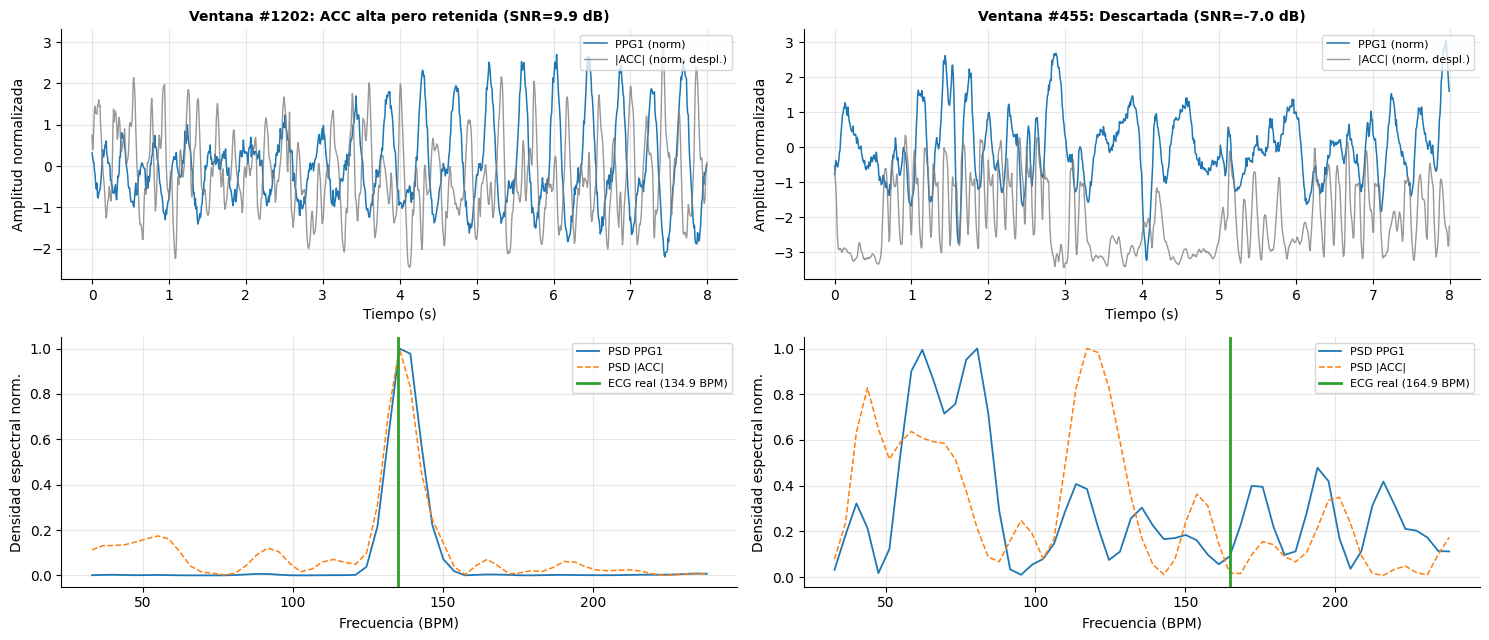

In [5]:
# --- Inspección visual: ventana retenida (ACC alta, espectro limpio) vs. descartada ---
snr_db = diag_sqi["snr_db"]
cand_val = np.where(diag_sqi["cond_acc_alta"] & m_val)[0]
cand_irr = np.where(m_irr)[0]

idx_val_ex = int(cand_val[np.nanargmax(snr_db[cand_val])]) if len(cand_val) else int(np.nanargmax(snr_db))
if len(cand_irr):
    idx_irr_ex = int(cand_irr[np.nanargmin(snr_db[cand_irr])])
    etiqueta_irr = "Descartada"
else:
    idx_irr_ex = int(np.nanargmin(snr_db))
    etiqueta_irr = "SNR más baja (ninguna descartada)"

print(f"Ventana retenida de ejemplo : #{idx_val_ex}")
print(f"Ventana descartada de ejemplo: #{idx_irr_ex} (descartadas en total: {len(cand_irr)})")

fig, axes = plt.subplots(2, 2, figsize=(15, 6.5))
t_vec = np.arange(WIN) / FS
freqs_plot = np.fft.rfftfreq(2048, d=1.0 / FS) * 60.0

for col, (idx, titulo) in enumerate([
    (idx_val_ex, f"Ventana #{idx_val_ex}: ACC alta pero retenida (SNR={snr_db[idx_val_ex]:.1f} dB)"),
    (idx_irr_ex, f"Ventana #{idx_irr_ex}: {etiqueta_irr} (SNR={snr_db[idx_irr_ex]:.1f} dB)"),
]):
    ppg_ex = X_test[idx, 0, :] - np.mean(X_test[idx, 0, :])
    acc_mag = np.linalg.norm(X_test[idx, 2:5, :] - np.mean(X_test[idx, 2:5, :], axis=-1, keepdims=True), axis=0)

    ax_t = axes[0, col]
    ax_t.plot(t_vec, ppg_ex / (np.std(ppg_ex) + 1e-9), label="PPG1 (norm)", color="#1f77b4", lw=1.1)
    ax_t.plot(t_vec, acc_mag / (np.std(acc_mag) + 1e-9) - 3.5, label="|ACC| (norm, despl.)", color="#7f7f7f", lw=1.0, alpha=0.8)
    ax_t.set_title(titulo, fontweight="bold", fontsize=10)
    ax_t.set_xlabel("Tiempo (s)")
    ax_t.set_ylabel("Amplitud normalizada")
    ax_t.legend(loc="upper right", fontsize=8)

    ax_f = axes[1, col]
    psd_ppg = np.abs(np.fft.rfft(ppg_ex * np.hanning(WIN), n=2048)) ** 2
    psd_acc = np.abs(np.fft.rfft((acc_mag - acc_mag.mean()) * np.hanning(WIN), n=2048)) ** 2
    mask_bpm = (freqs_plot >= 30) & (freqs_plot <= 240)
    ax_f.plot(freqs_plot[mask_bpm], psd_ppg[mask_bpm] / np.max(psd_ppg[mask_bpm]), label="PSD PPG1", color="#1f77b4", lw=1.3)
    ax_f.plot(freqs_plot[mask_bpm], psd_acc[mask_bpm] / np.max(psd_acc[mask_bpm]), label="PSD |ACC|", color="#ff7f0e", lw=1.1, ls="--")
    ax_f.axvline(y_test[idx], color="#2ca02c", lw=2, label=f"ECG real ({y_test[idx]:.1f} BPM)")
    ax_f.set_xlabel("Frecuencia (BPM)")
    ax_f.set_ylabel("Densidad espectral norm.")
    ax_f.legend(loc="upper right", fontsize=8)

plt.tight_layout()
save_fig(fig, "02_ejemplos_tiempo_espectro_sqi")
plt.show()

## 3. Evaluación comparativa: todas las ventanas vs. ventanas retenidas por el SQI

Dos escenarios:
1. **Dataset completo:** sin descartar nada.
2. **Dataset filtrado por SQI:** sin las ventanas descartadas en la sección 2 (la **misma máscara** para todos los algoritmos).

Y dos detectores:
- **Propio:** el detector óptimo de cada método. La línea base "Sin filtro" usa periodograma Hann con `nfft=8192`, que es la configuración que reproduce el 20.41 BPM de la presentación.
- **Común** (`nfft=4096`, Hamming): se aplica **a la señal limpia de cada filtro**, para aislar la ganancia del filtro adaptativo de la del estimador espectral.

Si alguna ventana diverge (salida `NaN`), se reemplaza por la predicción sin filtro y se informa cuántas fueron.

In [6]:
def fill_nan(p, fallback):
    p = np.asarray(p, dtype=float).copy()
    bad = ~np.isfinite(p)
    p[bad] = fallback[bad]
    return p, int(bad.sum())


def safe_mean(v):
    v = np.asarray(v, dtype=float)
    return float(np.mean(v)) if v.size else np.nan


COMMON_HR = dict(nfft=4096, window_type="hamming")

# --- Línea base: PPG1 y PPG2 fusionadas por SNR, sin filtro adaptativo ---
ppg1_t, ppg2_t, _ = preprocess_signal(X_test)          # batch (n, 5, N); NO pasar FS como 2º argumento posicional
d_fused_t = np.array([snr_weighted_late_fusion(ppg1_t[i], ppg2_t[i]) for i in range(len(X_test))])
pred_base_own = np.array([zero_padded_periodogram_bpm(s, nfft=8192) for s in d_fused_t])
pred_base_common = np.array([zero_padded_periodogram_bpm(s, **COMMON_HR) for s in d_fused_t])

preds = {"base": pred_base_own}
preds_common = {"base": pred_base_common}
elapsed = {"base": 0.0}
signals = {"base": d_fused_t}
n_nan = {"base": 0}

for k, m in models.items():
    t0 = time.perf_counter()
    p_own, sigs = m.predict_with_signals(X_test)            # una sola pasada: BPM propio + señal limpia
    elapsed[k] = time.perf_counter() - t0
    p_com = np.array([zero_padded_periodogram_bpm(s, **COMMON_HR) for s in sigs])
    preds[k], n1 = fill_nan(p_own, pred_base_own)
    preds_common[k], n2 = fill_nan(p_com, pred_base_common)
    signals[k] = sigs
    n_nan[k] = max(n1, n2)
    print(f"{LABELS[k]:<7} listo en {elapsed[k]:6.1f} s  (ventanas NaN reemplazadas: {n_nan[k]})")


def compute_metrics(y_true, y_pred, mask=None):
    if mask is not None:
        y_true, y_pred = y_true[mask], y_pred[mask]
    if len(y_true) == 0:
        return {"N": 0, "AAE": np.nan, "Mediana": np.nan, "RMSE": np.nan, "P90": np.nan, "Outliers_%": np.nan}
    err = np.abs(y_true - y_pred)
    return {
        "N": int(len(y_true)),
        "AAE": float(np.mean(err)),
        "Mediana": float(np.median(err)),
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "P90": float(np.percentile(err, 90)),
        "Outliers_%": float(100.0 * np.mean(err > OUTLIER_BPM)),
    }


def build_summary_table(pred_dict, mask=None, include_cv=True):
    rows = []
    for k in ORDER:
        m = compute_metrics(y_test, pred_dict[k], mask=mask)
        row = {
            "Algoritmo": LABELS[k], "N": m["N"],
            "AAE (BPM)": round(m["AAE"], 3), "Mediana": round(m["Mediana"], 3),
            "RMSE": round(m["RMSE"], 3), "P90": round(m["P90"], 3),
            f">{OUTLIER_BPM:.0f} BPM (%)": round(m["Outliers_%"], 2),
        }
        if include_cv:
            row["CV Train AAE"] = CV_AAE[k]
            row["Tiempo (s)"] = round(elapsed[k], 2)
        rows.append(row)
    return pd.DataFrame(rows)


print("\n=== 1A. GLOBAL (TODAS LAS VENTANAS - DETECTOR PROPIO) ===")
df_global_propio = build_summary_table(preds, mask=None, include_cv=True)
display(df_global_propio)

print("\n=== 1B. GLOBAL (TODAS LAS VENTANAS - DETECTOR COMÚN 4096/HAMMING) ===")
df_global_comun = build_summary_table(preds_common, mask=None, include_cv=False)
display(df_global_comun)

print(f"\n=== 2A. POST-SQI (VÁLIDAS: {int(diag_sqi['mask_valida'].sum())}/{len(y_test)} - DETECTOR PROPIO) ===")
df_sqi_propio = build_summary_table(preds, mask=diag_sqi["mask_valida"], include_cv=False)
display(df_sqi_propio)

print(f"\n=== 2B. POST-SQI (VÁLIDAS - DETECTOR COMÚN) ===")
df_sqi_comun = build_summary_table(preds_common, mask=diag_sqi["mask_valida"], include_cv=False)
display(df_sqi_comun)

LMS     listo en   12.7 s  (ventanas NaN reemplazadas: 0)


NLMS    listo en   19.3 s  (ventanas NaN reemplazadas: 0)


VS-LMS  listo en   20.8 s  (ventanas NaN reemplazadas: 0)


RLS     listo en   28.3 s  (ventanas NaN reemplazadas: 0)

=== 1A. GLOBAL (TODAS LAS VENTANAS - DETECTOR PROPIO) ===


,Algoritmo,N,AAE (BPM),Mediana,RMSE,P90,>10 BPM (%),CV Train AAE,Tiempo (s)
0,Sin filtro,1328,20.406,3.290,34.926,67.423,41.11,12.52,0.00
1,LMS,1328,13.089,1.389,29.268,62.373,21.99,5.18,12.74
2,NLMS,1328,12.530,1.276,27.793,55.497,22.74,3.82,19.25
3,VS-LMS,1328,12.642,1.315,27.673,55.330,23.19,4.04,20.81
4,RLS,1328,12.233,1.438,27.530,55.536,21.54,3.66,28.33



=== 1B. GLOBAL (TODAS LAS VENTANAS - DETECTOR COMÚN 4096/HAMMING) ===


,Algoritmo,N,AAE (BPM),Mediana,RMSE,P90,>10 BPM (%)
0,Sin filtro,1328,19.895,3.001,34.350,66.096,40.51
1,LMS,1328,13.089,1.389,29.268,62.373,21.99
2,NLMS,1328,12.665,1.401,27.946,55.053,22.82
3,VS-LMS,1328,12.699,1.414,27.701,54.845,23.27
4,RLS,1328,11.620,1.387,26.669,49.166,20.56



=== 2A. POST-SQI (VÁLIDAS: 1078/1328 - DETECTOR PROPIO) ===


,Algoritmo,N,AAE (BPM),Mediana,RMSE,P90,>10 BPM (%)
0,Sin filtro,1078,19.111,2.634,34.009,63.086,38.40
1,LMS,1078,13.359,1.357,29.683,64.359,22.54
2,NLMS,1078,13.112,1.263,28.748,61.994,23.56
3,VS-LMS,1078,13.347,1.301,28.923,59.547,24.03
4,RLS,1078,12.632,1.435,28.221,59.153,21.99



=== 2B. POST-SQI (VÁLIDAS - DETECTOR COMÚN) ===


,Algoritmo,N,AAE (BPM),Mediana,RMSE,P90,>10 BPM (%)
0,Sin filtro,1078,18.745,2.411,33.585,62.373,38.03
1,LMS,1078,13.359,1.357,29.683,64.359,22.54
2,NLMS,1078,13.223,1.363,28.896,62.109,23.56
3,VS-LMS,1078,13.414,1.414,28.946,59.547,24.12
4,RLS,1078,12.216,1.363,27.585,55.829,21.43


In [7]:
# --- Impacto cuantitativo del filtrado SQI por algoritmo ---
comp_sqi_rows = []
for k in ORDER:
    m_all = compute_metrics(y_test, preds[k], mask=None)
    m_v = compute_metrics(y_test, preds[k], mask=diag_sqi["mask_valida"])
    m_i = compute_metrics(y_test, preds[k], mask=diag_sqi["mask_irrecuperable"])
    comp_sqi_rows.append({
        "Algoritmo": LABELS[k],
        "AAE Global": round(m_all["AAE"], 3),
        "AAE Válidas (SQI)": round(m_v["AAE"], 3),
        "Reducción AAE (%)": round(100.0 * (m_all["AAE"] - m_v["AAE"]) / m_all["AAE"], 1),
        "AAE Descartadas": round(m_i["AAE"], 3) if m_i["N"] else np.nan,
        "Outliers Global (%)": round(m_all["Outliers_%"], 2),
        "Outliers Válidas (%)": round(m_v["Outliers_%"], 2),
    })
print("=== IMPACTO DEL CONTROL DE CALIDAD SQI EN CADA ALGORITMO ===")
print(f"Cobertura: se conserva {100 * diag_sqi['mask_valida'].mean():.1f}% de las ventanas "
      f"({int(diag_sqi['mask_valida'].sum())}/{len(y_test)}). Siempre reportar este número junto al AAE filtrado.")
display(pd.DataFrame(comp_sqi_rows))

=== IMPACTO DEL CONTROL DE CALIDAD SQI EN CADA ALGORITMO ===
Cobertura: se conserva 81.2% de las ventanas (1078/1328). Siempre reportar este número junto al AAE filtrado.


,Algoritmo,AAE Global,AAE Válidas (SQI),Reducción AAE (%),AAE Descartadas,Outliers Global (%),Outliers Válidas (%)
0,Sin filtro,20.406,19.111,6.3,25.991,41.11,38.40
1,LMS,13.089,13.359,-2.1,11.927,21.99,22.54
2,NLMS,12.530,13.112,-4.7,10.017,22.74,23.56
3,VS-LMS,12.642,13.347,-5.6,9.601,23.19,24.03
4,RLS,12.233,12.632,-3.3,10.509,21.54,21.99


### 3b. Control del SQI: ¿descarta ventanas más difíciles que el azar?

Filtrar ventanas siempre baja el AAE, así que hay que comprobar que el SQI sea **mejor que descartar la misma cantidad al azar**. Para cada algoritmo se compara el AAE tras el SQI con el de 1000 descartes aleatorios del mismo tamaño. El *p* empírico es la fracción de descartes aleatorios que logran un AAE igual o mejor: valores chicos (< 0.05) indican que el SQI selecciona ventanas realmente difíciles.

> La segunda tabla muestra la sensibilidad de los percentiles **sobre test, sólo como descripción**. Elegir los percentiles mirando el AAE de test sería *data leakage*; si querés optimizarlos, hacelo con ventanas de entrenamiento.

In [8]:
def control_aleatorio(err, mask_valida, n_draw=N_RANDOM_CTRL, seed=SEED):
    rng = np.random.default_rng(seed)
    N = len(err)
    n_disc = int((~mask_valida).sum())
    aae_sqi = float(err[mask_valida].mean())
    if n_disc == 0:
        return aae_sqi, np.nan, np.nan
    total = err.sum()
    draws = np.empty(n_draw)
    for b in range(n_draw):
        disc = rng.choice(N, size=n_disc, replace=False)
        draws[b] = (total - err[disc].sum()) / (N - n_disc)
    return aae_sqi, float(draws.mean()), float(np.mean(draws <= aae_sqi))


mv = diag_sqi["mask_valida"]
rows = []
for k in ["lms", "nlms", "vs_lms", "rls"]:
    err = np.abs(y_test - preds[k])
    aae_sqi, aae_rand, p_emp = control_aleatorio(err, mv)
    rows.append({"Algoritmo": LABELS[k], "AAE global": round(err.mean(), 3),
                 "AAE tras SQI": round(aae_sqi, 3), "AAE tras descarte aleatorio (media)": round(aae_rand, 3),
                 "p empírico": round(p_emp, 4)})
print(f"Descartadas: {int((~mv).sum())} de {len(mv)} ({100 * (~mv).mean():.1f}%)")
display(pd.DataFrame(rows))

# Sensibilidad (descriptiva, sobre test): conteo y AAE de NLMS y RLS en las retenidas
rows = []
err_n, err_r = np.abs(y_test - preds["nlms"]), np.abs(y_test - preds["rls"])
for p_acc in [65, 75, 85]:
    for p_snr in [15, 25, 35]:
        d_t = evaluar_criterio_dual_sqi(met_test, calibrar_umbrales_sqi(met_train, p_acc, p_snr))
        v = d_t["mask_valida"]
        rows.append({"P_ACC": f"P{p_acc}", "P_SNR": f"P{p_snr}",
                     "Descartadas (%)": round(100 * (~v).mean(), 2),
                     "AAE NLMS": round(safe_mean(err_n[v]), 3), "AAE RLS": round(safe_mean(err_r[v]), 3),
                     "NLMS - RLS": round(safe_mean(err_n[v]) - safe_mean(err_r[v]), 3)})
print("\nSensibilidad de los percentiles (descriptiva, test):")
display(pd.DataFrame(rows))

Descartadas: 250 de 1328 (18.8%)


,Algoritmo,AAE global,AAE tras SQI,AAE tras descarte aleatorio (media),p empírico
0,LMS,13.089,13.359,13.108,0.757
1,NLMS,12.530,13.112,12.538,0.962
2,VS-LMS,12.642,13.347,12.644,0.988
3,RLS,12.233,12.632,12.246,0.881



Sensibilidad de los percentiles (descriptiva, test):


,P_ACC,P_SNR,Descartadas (%),AAE NLMS,AAE RLS,NLMS - RLS
0,P65,P15,16.94,12.996,12.685,0.311
1,P65,P25,21.99,13.283,12.921,0.362
2,P65,P35,25.45,13.494,13.317,0.177
3,P75,P15,14.31,12.919,12.493,0.427
4,P75,P25,18.83,13.112,12.632,0.480
5,P75,P35,22.14,13.287,12.976,0.311
6,P85,P15,12.58,12.835,12.421,0.413
7,P85,P25,16.94,12.997,12.533,0.464
8,P85,P35,20.03,13.129,12.832,0.296


## 4. Intervalos de Confianza (Bootstrap Estratificado por Sujeto)

Calculamos intervalos de confianza al 95% remuestreando **participantes completos** con reemplazo (`N_BOOT = 2000`), evaluando tanto el dataset completo como las ventanas válidas tras SQI.

In [9]:
def subject_bootstrap_ci(y_true, pred_a, pred_b, groups, mask=None, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    if mask is not None:
        y_true = y_true[mask]
        pred_a = pred_a[mask]
        pred_b = pred_b[mask]
        groups = groups[mask]

    uniq = np.unique(groups)
    err_a = np.abs(y_true - pred_a)
    err_b = np.abs(y_true - pred_b)
    idx_by_s = [np.where(groups == s)[0] for s in uniq]

    diffs = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, len(uniq), size=len(uniq))
        idx = np.concatenate([idx_by_s[p] for p in pick])
        diffs[b] = err_a[idx].mean() - err_b[idx].mean()
    return float(diffs.mean()), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

boot_rows = []
for escenario, msk in [("Global (Todas las ventanas)", None), ("Filtrado SQI (Ventanas válidas)", diag_sqi["mask_valida"])]:
    for ref in ["base", "lms", "nlms", "vs_lms"]:
        mean_d, lo, hi = subject_bootstrap_ci(y_test, preds[ref], preds["rls"], test_groups, mask=msk, n_boot=N_BOOT, seed=SEED)
        boot_rows.append({
            "Escenario": escenario,
            "Comparación": f"{LABELS[ref]} - RLS",
            "Δ AAE Medio (BPM)": round(mean_d, 3),
            "IC 95% Inf": round(lo, 3),
            "IC 95% Sup": round(hi, 3),
            "Conclusión (IC 95%)": "RLS mejor" if lo > 0 else ("RLS peor" if hi < 0 else "No concluyente"),
        })

display(pd.DataFrame(boot_rows))

,Escenario,Comparación,Δ AAE Medio (BPM),IC 95% Inf,IC 95% Sup,Conclusión (IC 95%)
0,Global (Todas las ventanas),Sin filtro - RLS,8.124,2.217,13.267,RLS mejor
1,Global (Todas las ventanas),LMS - RLS,0.888,-0.927,2.903,No concluyente
2,Global (Todas las ventanas),NLMS - RLS,0.294,-0.935,1.435,No concluyente
3,Global (Todas las ventanas),VS-LMS - RLS,0.418,-0.635,1.471,No concluyente
4,Filtrado SQI (Ventanas válidas),Sin filtro - RLS,6.539,0.701,12.468,RLS mejor
5,Filtrado SQI (Ventanas válidas),LMS - RLS,0.763,-1.226,3.003,No concluyente
6,Filtrado SQI (Ventanas válidas),NLMS - RLS,0.493,-0.964,1.893,No concluyente
7,Filtrado SQI (Ventanas válidas),VS-LMS - RLS,0.734,-0.582,2.147,No concluyente


## 5. Dispersión BPM y Rendimiento por Sujeto

Visualizamos las predicciones frente a la referencia ECG real diferenciando las **ventanas válidas** de las **ventanas irrecuperables (SQI)**, además de comparar el AAE por participante en ambos escenarios.

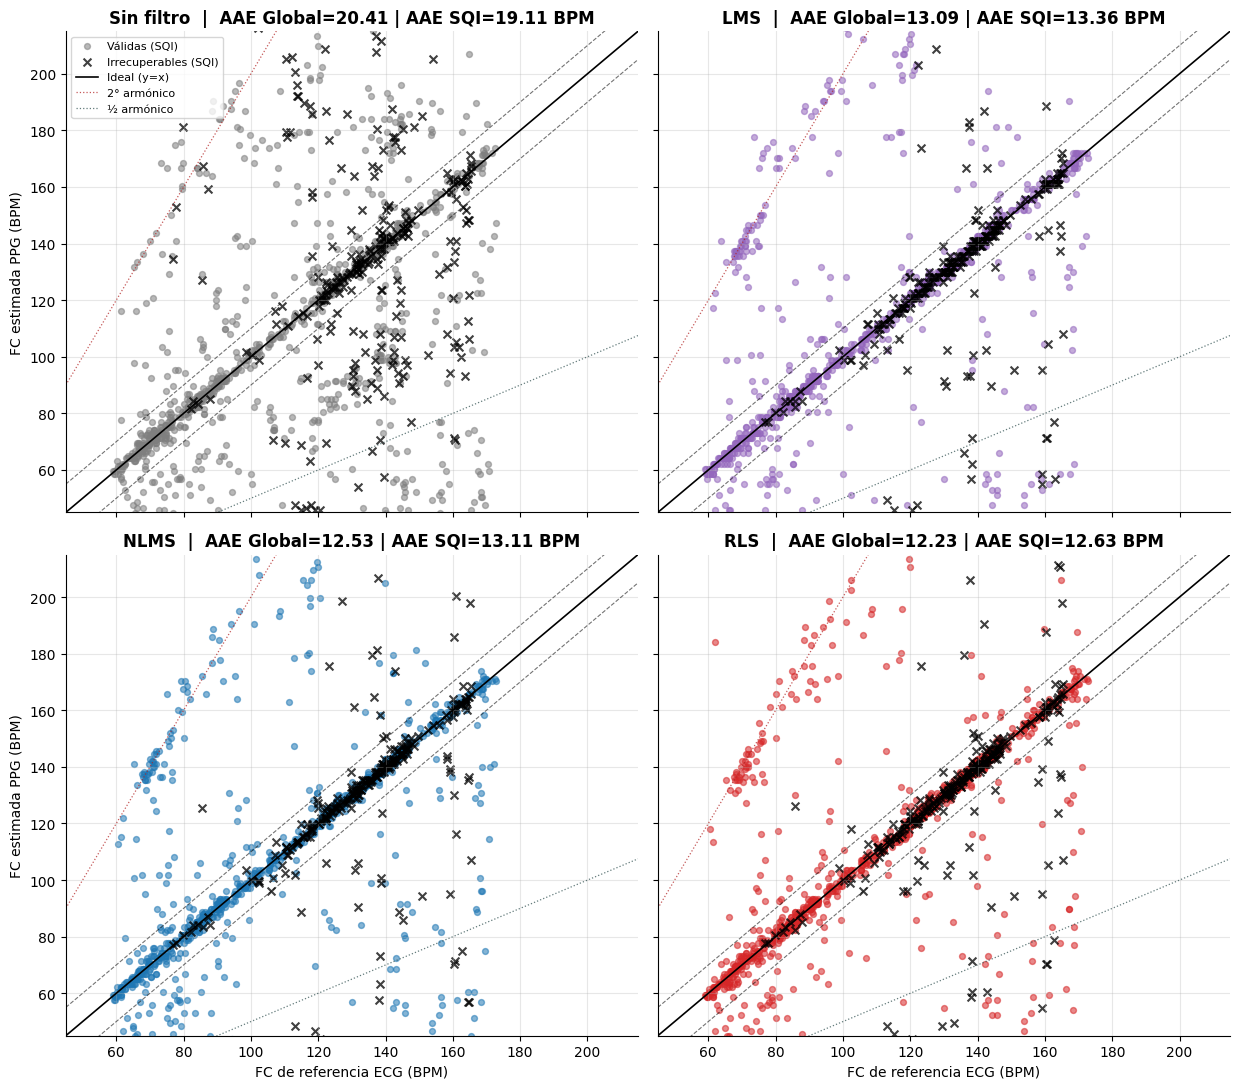

In [10]:
# --- Dispersión Predicción vs. Realidad (marcando ventanas irrecuperables SQI) ---
fig, axes = plt.subplots(2, 2, figsize=(12.5, 11), sharex=True, sharey=True)
lims = [45, 215]
grid = np.linspace(*lims, 200)
m_val = diag_sqi["mask_valida"]
m_irr = diag_sqi["mask_irrecuperable"]

for ax, k in zip(axes.ravel(), ["base", "lms", "nlms", "rls"]):
    ax.scatter(y_test[m_val], preds[k][m_val], s=18, alpha=0.55, color=COLORS[k], label="Válidas (SQI)")
    ax.scatter(y_test[m_irr], preds[k][m_irr], s=32, marker="x", color="black", alpha=0.75, label="Irrecuperables (SQI)")
    ax.plot(grid, grid, "k-", lw=1.2, label="Ideal (y=x)")
    ax.plot(grid, grid + OUTLIER_BPM, "k--", lw=0.8, alpha=0.55)
    ax.plot(grid, grid - OUTLIER_BPM, "k--", lw=0.8, alpha=0.55)
    ax.plot(grid, 2 * grid, ":", color="#b22222", lw=0.9, alpha=0.75, label="2° armónico")
    ax.plot(grid, 0.5 * grid, ":", color="#2f4f4f", lw=0.9, alpha=0.75, label="½ armónico")

    aae_all = np.mean(np.abs(y_test - preds[k]))
    aae_sqi = np.mean(np.abs(y_test[m_val] - preds[k][m_val]))
    ax.set_title(f"{LABELS[k]}  |  AAE Global={aae_all:.2f} | AAE SQI={aae_sqi:.2f} BPM", fontweight="bold")
    ax.set_xlim(lims)
    ax.set_ylim(lims)

for ax in axes[1]:
    ax.set_xlabel("FC de referencia ECG (BPM)")
for ax in axes[:, 0]:
    ax.set_ylabel("FC estimada PPG (BPM)")
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
save_fig(fig, "03_dispersion_bpm_con_sqi")
plt.show()

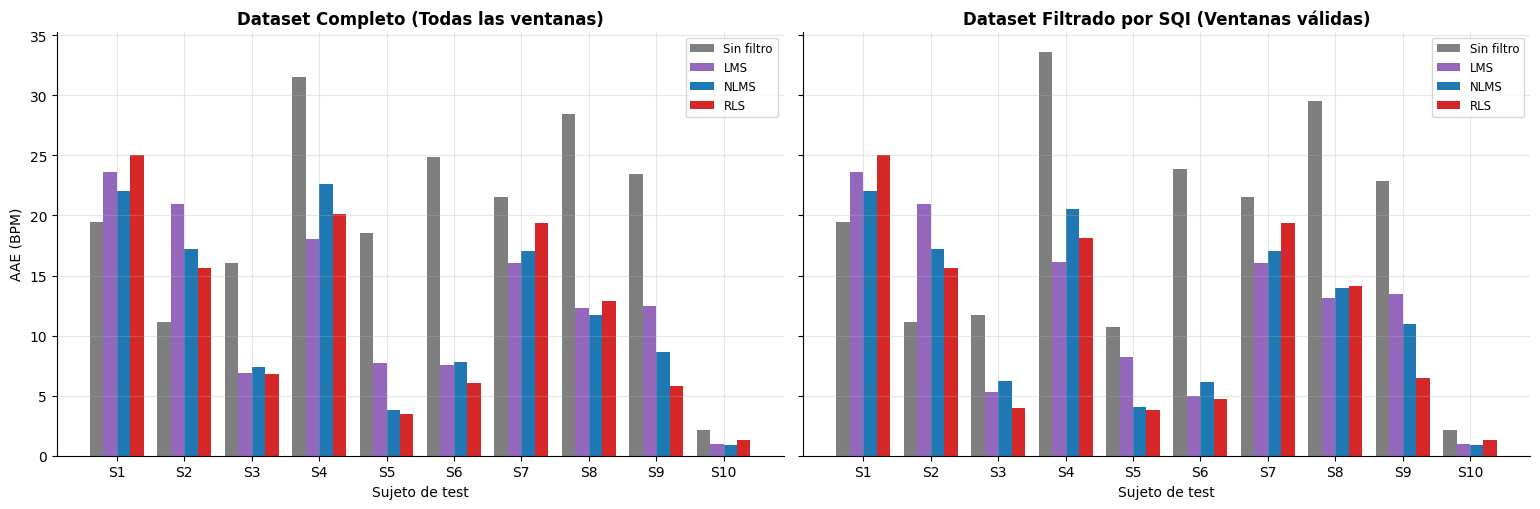

In [11]:
# --- Rendimiento por Sujeto: Global vs. Filtrado SQI ---
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), sharey=True)
x = np.arange(len(subjects))
w = 0.20

for ax, (titulo, msk) in zip(axes, [
    ("Dataset Completo (Todas las ventanas)", None),
    ("Dataset Filtrado por SQI (Ventanas válidas)", diag_sqi["mask_valida"])
]):
    for j, k in enumerate(["base", "lms", "nlms", "rls"]):
        vals = []
        for s in subjects:
            cond = (test_groups == s) if msk is None else ((test_groups == s) & msk)
            vals.append(safe_mean(np.abs(y_test[cond] - preds[k][cond])))
        ax.bar(x + (j - 1.5) * w, vals, width=w, color=COLORS[k], label=LABELS[k])
    ax.set_xticks(x)
    ax.set_xticklabels([f"S{int(s) + 1}" for s in subjects])
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Sujeto de test")
    ax.legend(fontsize=8.5)

axes[0].set_ylabel("AAE (BPM)")
plt.tight_layout()
save_fig(fig, "04_aae_por_sujeto_global_vs_sqi")
plt.show()

## 6. Impacto del Ruido por Régimen de Movimiento y Calidad Espectral

Analizamos cómo se comporta cada filtro adaptativo según el cuartil de energía dinámica del acelerómetro ($E_{ACC}$) y el régimen de $SNR_{card}$, comparando el dataset completo frente al filtrado por SQI.

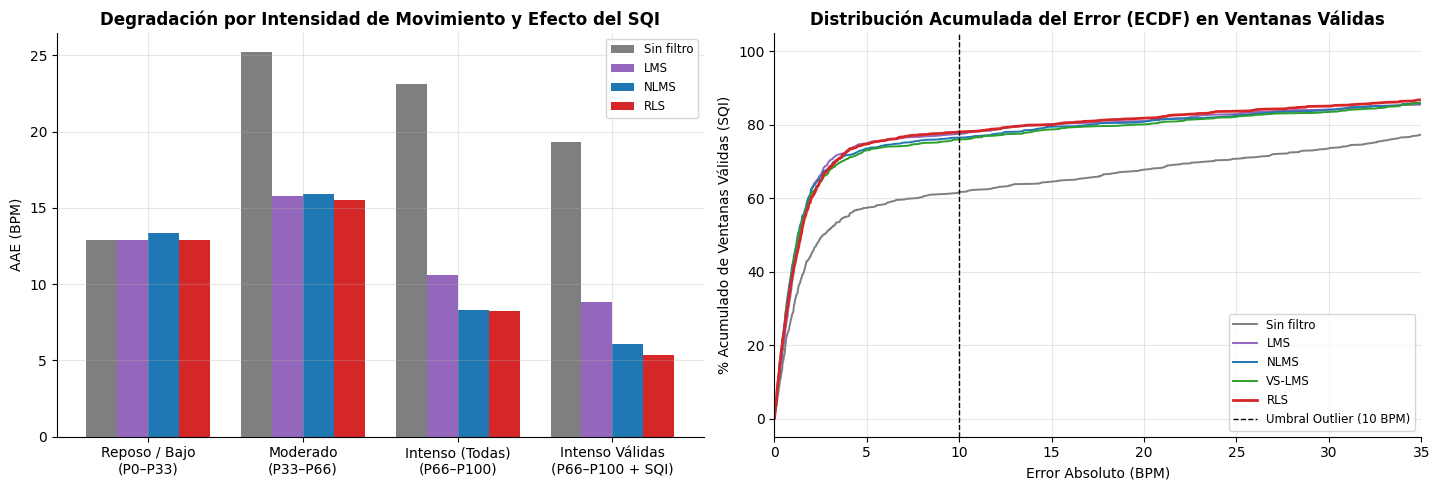

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))

# Panel A: AAE por tercil de Energía ACC (Global vs SQI)
q33, q66 = np.percentile(diag_sqi["e_acc"], [33.3, 66.7])
regimenes = [
    ("Reposo / Bajo\n(P0–P33)", diag_sqi["e_acc"] <= q33),
    ("Moderado\n(P33–P66)", (diag_sqi["e_acc"] > q33) & (diag_sqi["e_acc"] <= q66)),
    ("Intenso (Todas)\n(P66–P100)", diag_sqi["e_acc"] > q66),
    ("Intenso Válidas\n(P66–P100 + SQI)", (diag_sqi["e_acc"] > q66) & diag_sqi["mask_valida"]),
]

x_reg = np.arange(len(regimenes))
w = 0.20
ax = axes[0]
for j, k in enumerate(["base", "lms", "nlms", "rls"]):
    aaes = [np.mean(np.abs(y_test[m] - preds[k][m])) for _, m in regimenes]
    ax.bar(x_reg + (j - 1.5) * w, aaes, width=w, color=COLORS[k], label=LABELS[k])
ax.set_xticks(x_reg)
ax.set_xticklabels([r[0] for r in regimenes])
ax.set_ylabel("AAE (BPM)")
ax.set_title("Degradación por Intensidad de Movimiento y Efecto del SQI", fontweight="bold")
ax.legend(fontsize=8.5)

# Panel B: Curva acumulada de error (ECDF) en ventanas válidas (SQI)
ax = axes[1]
m_val = diag_sqi["mask_valida"]
for k in ORDER:
    err_sorted = np.sort(np.abs(y_test[m_val] - preds[k][m_val]))
    ecdf = np.arange(1, len(err_sorted) + 1) / len(err_sorted) * 100.0
    ax.plot(err_sorted, ecdf, color=COLORS[k], lw=2.0 if k == "rls" else 1.4, label=LABELS[k])

ax.axvline(OUTLIER_BPM, color="black", linestyle="--", lw=1.0, label=f"Umbral Outlier ({OUTLIER_BPM:.0f} BPM)")
ax.set_xlim(0, 35)
ax.set_xlabel("Error Absoluto (BPM)")
ax.set_ylabel("% Acumulado de Ventanas Válidas (SQI)")
ax.set_title("Distribución Acumulada del Error (ECDF) en Ventanas Válidas", fontweight="bold")
ax.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
save_fig(fig, "05_regimenes_movimiento_y_ecdf")
plt.show()